# Pipeline Penelitian Disertasi: Imbalance-Aware Modified PSO untuk Seleksi Fitur Multilabel

Ujicoba ini untuk menyesuaikan eksperimen dengan kontribusi penelitian disertasi, yaitu pengembangan metode seleksi fitur untuk klasifikasi multilabel umpan balik mahasiswa dengan ketidakseimbangan label.

Fokus utama eksperimen:

1. Membaca dan membersihkan dataset umpan balik mahasiswa secara aman.
2. Melakukan preprocessing teks sebelum pemisahan data.
3. Menghasilkan representasi fitur menggunakan IndoBERT, dengan TF-IDF sebagai fallback.
4. Menangani ketidakseimbangan label hanya pada data training menggunakan MLSMOTE.
5. Menjalankan baseline tanpa seleksi fitur.
6. Menjalankan seleksi fitur statistik sebagai pembanding dan sebagai tahap penyaringan awal.
7. Menjalankan Standard PSO sebagai pembanding metaheuristik.
8. Menjalankan metode usulan **Imbalance-Aware Modified PSO** sebagai optimasi subset fitur setelah penyaringan statistik.
9. Menggunakan fungsi objektif yang mempertimbangkan kualitas klasifikasi, sensitivitas label minoritas, efisiensi jumlah fitur, dan redundansi fitur.
10. Menampilkan tabel perbandingan hasil, jumlah fitur, dan performa per label.

Catatan penting:

- Data testing tidak pernah digunakan dalam MLSMOTE, seleksi fitur, atau proses optimasi.
- Evaluasi akhir tetap dilakukan pada data testing asli.
- Label minoritas ditentukan dari distribusi label pada data training sebelum MLSMOTE.
- Metode usulan pada Ujicoba ini adalah **Statistical Screening + Imbalance-Aware Modified PSO**.


In [1]:
# ============================================================
# 1. Instalasi library
# ============================================================
%pip install -q gdown transformers Sastrawi tqdm scikit-learn matplotlib joblib openpyxl


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 3.8 MB/s eta 0:00:00


In [2]:
# ============================================================
# 2. Import library dan konfigurasi utama
# ============================================================
import os
import re
import random
import hashlib
import warnings
from pathlib import Path

import gdown
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import VarianceThreshold, f_classif, mutual_info_classif
from sklearn.neighbors import NearestNeighbors
from sklearn.ensemble import RandomForestClassifier
from sklearn.multioutput import MultiOutputClassifier
from sklearn.metrics import accuracy_score, hamming_loss, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Nama file
DATA_PATH = Path("cleaned_df.csv")
ACRONYM_PATH = Path("acronym.txt")
KBBA_PATH = Path("kbba.txt")
STOPWORDS_PATH = Path("stopwordsID.txt")

# Kolom dataset
TEXT_COL = "saran"
CLEAN_TEXT_COL = "text_clean"
LABELS = ["SU", "DPAL", "DSTI", "DA", "DPMBKA", "DK", "Perpustakaan"]

# Konfigurasi embedding
MODEL_NAME = "indobenchmark/indobert-base-p1"
MAX_LEN = 128
BATCH_SIZE = 16
TEST_SIZE = 0.20
CACHE_DIR = Path("cache_embedding")
CACHE_DIR.mkdir(exist_ok=True)

# Konfigurasi seleksi fitur statistik
# Nilai ini dibuat sebagai grid agar hasil tidak terkunci pada 200 fitur saja.
FEATURE_TOP_K_LIST = [50, 100, 150, 200, 300, 500]
THETA_VT = 0.0
RELIEF_SAMPLE_SIZE = 400

# Konfigurasi kandidat fitur untuk metode usulan
# Tahap 1 menyaring fitur statistik. Tahap 2 mengoptimasi subset memakai IA-MPSO.
DEFAULT_CANDIDATE_TOP_K = 300
MIN_SELECTED_FEATURES = 20
MAX_FEATURE_RATIO = 0.70

# Konfigurasi Random Forest evaluasi akhir
RF_N_ESTIMATORS = 150
RF_MAX_DEPTH = 14

# Konfigurasi Random Forest di dalam fitness agar proses optimasi tidak terlalu berat
FITNESS_RF_N_ESTIMATORS = 70
FITNESS_RF_MAX_DEPTH = 10
CV_SPLITS = 3

# Konfigurasi PSO
PSO_POP_SIZE = 12
PSO_MAX_ITER = 15
PSO_PATIENCE = 5
W_MAX = 0.90
W_MIN = 0.40
C1 = 1.70
C2 = 1.70
RELEVANCE_BIAS = 1.20

# Bobot fungsi objektif metode usulan
# Kualitas klasifikasi dan sensitivitas label minoritas diberi bobot utama.
OBJ_W_WEIGHTED_F1 = 0.30
OBJ_W_MACRO_F1 = 0.20
OBJ_W_MINOR_RECALL = 0.30
OBJ_W_HAMMING = 0.10
OBJ_W_SUBSET_SIZE = 0.06
OBJ_W_REDUNDANCY = 0.04

print("Konfigurasi selesai.")


Konfigurasi selesai.


In [3]:
# ============================================================
# 3. Download dataset dan file pendukung jika belum tersedia
# ============================================================
FILES = {
    "acronym.txt": "1i-_dpAtulIM2gdfk6mXbfi_tfoqWz036",
    "cleaned_df.csv": "1Dtp7emDjco9BeKbZPS6P5ImQXVmNPGyM",
    "kbba.txt": "1OeRk-QnxogCvTGZiYN2hHYqqMpUuFYhk",
    "stopwordsID.txt": "1_8NjGVBjnx_7OrjvjgFAM2wvnJSNK6qf",
}


def download_if_missing(filename, file_id):
    path = Path(filename)
    if path.exists() and path.stat().st_size > 0:
        print(f"File sudah ada: {filename}")
        return path

    print(f"Mengunduh {filename} ...")
    url = f"https://drive.google.com/uc?id={file_id}"
    gdown.download(url, str(path), quiet=False)

    if not path.exists() or path.stat().st_size == 0:
        raise FileNotFoundError(
            f"{filename} belum tersedia. Upload file ini ke folder kerja atau cek akses Google Drive."
        )
    return path


for filename, file_id in FILES.items():
    download_if_missing(filename, file_id)

print("Semua file utama sudah tersedia.")


Mengunduh acronym.txt ...


Downloading...
From: https://drive.google.com/uc?id=1i-_dpAtulIM2gdfk6mXbfi_tfoqWz036
To: /content/acronym.txt
100%|██████████| 141k/141k [00:00<00:00, 58.5MB/s]


Mengunduh cleaned_df.csv ...


Downloading...
From: https://drive.google.com/uc?id=1Dtp7emDjco9BeKbZPS6P5ImQXVmNPGyM
To: /content/cleaned_df.csv
100%|██████████| 9.07M/9.07M [00:00<00:00, 74.4MB/s]


Mengunduh kbba.txt ...


Downloading...
From: https://drive.google.com/uc?id=1OeRk-QnxogCvTGZiYN2hHYqqMpUuFYhk
To: /content/kbba.txt
100%|██████████| 20.8k/20.8k [00:00<00:00, 32.1MB/s]


Mengunduh stopwordsID.txt ...


Downloading...
From: https://drive.google.com/uc?id=1_8NjGVBjnx_7OrjvjgFAM2wvnJSNK6qf
To: /content/stopwordsID.txt
100%|██████████| 6.45k/6.45k [00:00<00:00, 3.79MB/s]

Semua file utama sudah tersedia.


In [4]:
# ============================================================
# 4. Fungsi preprocessing teks
# ============================================================
try:
    from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
    stemmer = StemmerFactory().create_stemmer()
except Exception:
    stemmer = None


def load_dictionary(path, separator, skip_first=False):
    data = {}
    path = Path(path)
    if not path.exists():
        return data

    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        lines = f.readlines()

    if skip_first and len(lines) > 0:
        lines = lines[1:]

    for line in lines:
        line = line.strip()
        if not line or separator not in line:
            continue
        key, value = line.split(separator, 1)
        key = key.strip().lower()
        value = value.strip().lower()
        if key and value:
            data[key] = value
    return data


def load_stopwords(path):
    path = Path(path)
    if not path.exists():
        return {
            "yang", "dan", "di", "ke", "dari", "ini", "itu", "untuk",
            "dengan", "pada", "adalah", "karena", "atau", "sebagai",
            "dalam", "saya", "kami", "mereka", "ada", "agar"
        }

    words = []
    with open(path, "r", encoding="utf-8", errors="ignore") as f:
        for line in f:
            word = line.strip().lower()
            if word:
                words.append(word)

    stop_words = set(words)
    # Kata negasi dan intensitas penting untuk konteks keluhan, jadi tidak dihapus.
    stop_words = stop_words - {"kurang", "banyak", "tidak", "belum", "jangan"}
    return stop_words


ACRONYM = load_dictionary(ACRONYM_PATH, "=")
SLANG = load_dictionary(KBBA_PATH, "	")
STOP_WORDS = load_stopwords(STOPWORDS_PATH)


def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"@\w+|#\w+", " ", text)
    text = re.sub(r"[^a-zA-ZÀ-ÿ\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    tokens = text.split()
    tokens = [ACRONYM.get(token, token) for token in tokens]
    tokens = [SLANG.get(token, token) for token in tokens]
    tokens = [token for token in tokens if token not in STOP_WORDS]

    if stemmer is not None:
        tokens = [stemmer.stem(token) for token in tokens]

    return " ".join(tokens).strip()


print("Jumlah acronym:", len(ACRONYM))
print("Jumlah slang   :", len(SLANG))
print("Jumlah stopword:", len(STOP_WORDS))


Jumlah acronym: 4029
Jumlah slang   : 1290
Jumlah stopword: 752


In [5]:
# ============================================================
# 5. Load dataset, hapus baris kosong, dan validasi label
# ============================================================
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = df.columns.str.strip()

required_cols = [TEXT_COL] + LABELS
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Kolom berikut tidak ditemukan dalam dataset: {missing_cols}")

print("Jumlah baris awal:", len(df))

# Hapus baris tanpa teks agar embedding tidak memproses data kosong.
df = df.dropna(subset=[TEXT_COL]).copy()
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df = df[df[TEXT_COL].ne("")].copy()

# Bersihkan label agar selalu numerik biner 0/1.
for label in LABELS:
    df[label] = pd.to_numeric(df[label], errors="coerce")

df[LABELS] = df[LABELS].replace([np.inf, -np.inf], np.nan).fillna(0)
df[LABELS] = df[LABELS].clip(0, 1).astype(int)

# Preprocessing teks dilakukan sebelum split agar kolom yang dipakai konsisten.
df[CLEAN_TEXT_COL] = df[TEXT_COL].apply(clean_text)
df = df[df[CLEAN_TEXT_COL].str.strip().ne("")].copy()
df = df.reset_index(drop=True)

print("Jumlah baris valid setelah pembersihan:", len(df))
print("Shape dataset:", df.shape)
print("\nDistribusi label:")
print(df[LABELS].sum().sort_values(ascending=False))

display(df[[TEXT_COL, CLEAN_TEXT_COL] + LABELS].head())


Jumlah baris awal: 987734
Jumlah baris valid setelah pembersihan: 3229
Shape dataset: (3229, 9)

Distribusi label:
DSTI            1205
DPAL             895
SU               563
Perpustakaan     247
DA               155
DK                43
DPMBKA            39
dtype: int64


,saran,text_clean,SU,DPAL,DSTI,DA,DPMBKA,DK,Perpustakaan
0,Fasilitas kurang mendukung,fasilitas kurang dukung,1,1,0,0,0,0,0
1,Wifi kurang lancar,wireless fidelity kurang lancar,0,0,1,0,0,0,0
2,Usahakan kalo kepada mahasiswa yg lupa atau ke...,usaha mahasiswa lupa tinggal bawa surat tanda ...,1,1,0,0,0,0,0
3,Mohon untuk wifi di perbaiki lagi,mohon wireless fidelity daerah istimewa baik,0,0,1,0,0,0,0
4,Parkiran kampus,parkir kampus,1,1,0,0,0,0,0


Distribusi label dan indikasi label minoritas:


,Label,Positive Count,Imbalance Ratio to Max,Minority by Mean
0,DSTI,1205,1.0000,False
1,DPAL,895,1.3464,False
2,SU,563,2.1403,False
3,Perpustakaan,247,4.8785,True
4,DA,155,7.7742,True
5,DK,43,28.0233,True
6,DPMBKA,39,30.8974,True


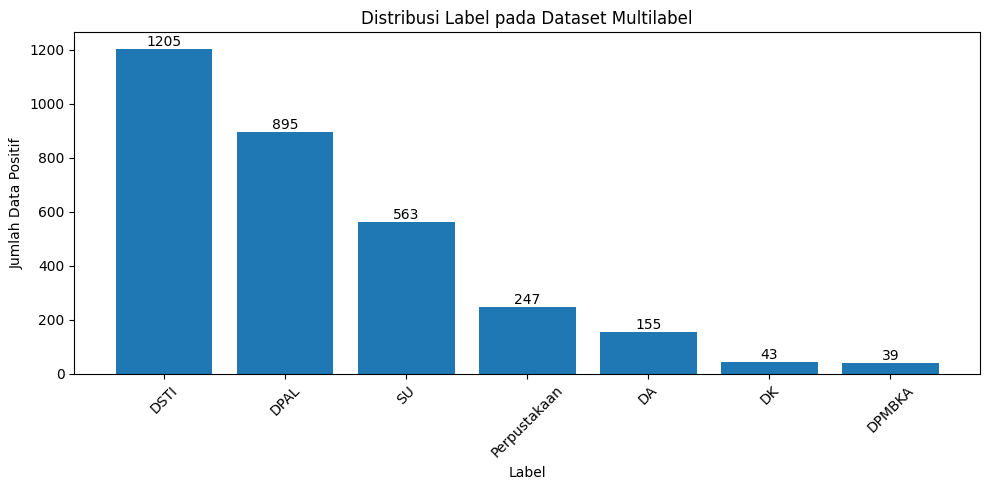

In [6]:
# ============================================================
# 6. Analisis distribusi label dan ketidakseimbangan multilabel
# ============================================================
label_counts = df[LABELS].sum().sort_values(ascending=False)
max_count = label_counts.max()
mean_count = label_counts.mean()

label_distribution_df = pd.DataFrame({
    "Label": label_counts.index,
    "Positive Count": label_counts.values,
    "Imbalance Ratio to Max": (max_count / label_counts.values).round(4),
    "Minority by Mean": label_counts.values < mean_count
})

print("Distribusi label dan indikasi label minoritas:")
display(label_distribution_df)

plt.figure(figsize=(10, 5))
bars = plt.bar(label_counts.index, label_counts.values)
plt.title("Distribusi Label pada Dataset Multilabel")
plt.xlabel("Label")
plt.ylabel("Jumlah Data Positif")
plt.xticks(rotation=45)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        int(height),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [7]:
# ============================================================
# 7. Train-test split yang aman untuk multilabel
# ============================================================
def safe_multilabel_split(X, Y, test_size=0.2, random_state=42, max_trials=100):
    # Mencari split yang tetap memiliki minimal satu data positif untuk setiap label pada train dan test.
    for seed in range(random_state, random_state + max_trials):
        X_train, X_test, Y_train, Y_test = train_test_split(
            X,
            Y,
            test_size=test_size,
            random_state=seed,
            shuffle=True
        )
        if (Y_train.sum(axis=0) > 0).all() and (Y_test.sum(axis=0) > 0).all():
            print(f"Split aman ditemukan dengan random_state={seed}")
            return X_train, X_test, Y_train, Y_test, seed

    print("Peringatan: split aman tidak ditemukan. Menggunakan random_state awal.")
    X_train, X_test, Y_train, Y_test = train_test_split(
        X,
        Y,
        test_size=test_size,
        random_state=random_state,
        shuffle=True
    )
    return X_train, X_test, Y_train, Y_test, random_state


X_text = df[CLEAN_TEXT_COL].astype(str).values
Y = df[LABELS].astype(int).values

X_train_text, X_test_text, Y_train, Y_test, SPLIT_RANDOM_STATE = safe_multilabel_split(
    X_text,
    Y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

train_label_counts = Y_train.sum(axis=0)
train_mean_count = train_label_counts.mean()
MINORITY_LABEL_INDICES = np.where(train_label_counts < train_mean_count)[0]
if len(MINORITY_LABEL_INDICES) == 0:
    MINORITY_LABEL_INDICES = np.arange(len(LABELS))
MINORITY_LABELS = [LABELS[i] for i in MINORITY_LABEL_INDICES]

print("Jumlah data train:", len(X_train_text))
print("Jumlah data test :", len(X_test_text))
print("Shape Y_train    :", Y_train.shape)
print("Shape Y_test     :", Y_test.shape)
print("Label minoritas berdasarkan data training asli:", MINORITY_LABELS)

print("\nDistribusi label train:")
print(pd.Series(Y_train.sum(axis=0), index=LABELS).sort_values(ascending=False))
print("\nDistribusi label test:")
print(pd.Series(Y_test.sum(axis=0), index=LABELS).sort_values(ascending=False))


Split aman ditemukan dengan random_state=42
Jumlah data train: 2583
Jumlah data test : 646
Shape Y_train    : (2583, 7)
Shape Y_test     : (646, 7)
Label minoritas berdasarkan data training asli: ['DA', 'DPMBKA', 'DK', 'Perpustakaan']

Distribusi label train:
DSTI            975
DPAL            697
SU              460
Perpustakaan    199
DA              126
DPMBKA           35
DK               33
dtype: int64

Distribusi label test:
DSTI            230
DPAL            198
SU              103
Perpustakaan     48
DA               29
DK               10
DPMBKA            4
dtype: int64


In [8]:
# ============================================================
# 8. Ekstraksi embedding: IndoBERT dengan fallback TF-IDF
# ============================================================
try:
    import torch
    from transformers import AutoTokenizer, AutoModel
except Exception as e:
    torch = None
    AutoTokenizer = None
    AutoModel = None
    print("Torch/Transformers belum dapat digunakan:", repr(e))


class BertEmbedder:
    def __init__(self, model_name, max_len=128, device=None):
        if torch is None or AutoTokenizer is None or AutoModel is None:
            raise ImportError("Torch atau Transformers tidak tersedia.")

        self.model_name = model_name
        self.max_len = max_len
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")

        print("Device yang digunakan:", self.device)
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name)
        self.model.to(self.device)
        self.model.eval()

    def encode(self, texts, batch_size=16):
        texts = [str(text) for text in texts]
        embeddings = []

        for i in tqdm(range(0, len(texts), batch_size), desc="Extracting BERT embeddings"):
            batch_texts = texts[i:i + batch_size]
            encoded = self.tokenizer(
                batch_texts,
                padding=True,
                truncation=True,
                max_length=self.max_len,
                return_tensors="pt"
            )
            encoded = {key: value.to(self.device) for key, value in encoded.items()}

            with torch.no_grad():
                outputs = self.model(**encoded)
                cls_embedding = outputs.last_hidden_state[:, 0, :]

            embeddings.append(cls_embedding.cpu().numpy())

        return np.vstack(embeddings).astype(np.float32)


def make_cache_name(prefix, texts, model_name):
    sample = " ".join([str(x) for x in texts[:30]])
    raw_key = f"{prefix}_{len(texts)}_{model_name}_{SPLIT_RANDOM_STATE}_{sample}"
    digest = hashlib.md5(raw_key.encode("utf-8")).hexdigest()[:10]
    safe_model = re.sub(r"[^a-zA-Z0-9]+", "_", model_name).strip("_")
    return f"{prefix}_{safe_model}_{len(texts)}_{digest}"


def encode_with_resume(texts, embedder, name, batch_size=16, chunk_size=500, cache_dir=CACHE_DIR):
    texts = [str(text) for text in texts]
    cache_dir = Path(cache_dir)
    cache_dir.mkdir(exist_ok=True)

    final_path = cache_dir / f"{name}_final.npy"
    if final_path.exists():
        embeddings = np.load(final_path)
        if embeddings.shape[0] == len(texts):
            print(f"Loading final embedding: {final_path}")
            return embeddings
        print("Cache final tidak cocok dengan jumlah data saat ini. Embedding dibuat ulang.")
        final_path.unlink()

    total_chunks = (len(texts) + chunk_size - 1) // chunk_size
    chunk_paths = []

    for i in tqdm(range(total_chunks), desc=f"Encoding {name}"):
        start = i * chunk_size
        end = min((i + 1) * chunk_size, len(texts))
        chunk_path = cache_dir / f"{name}_chunk_{i}.npy"
        temp_path = chunk_path.with_suffix(".tmp.npy")
        chunk_paths.append(chunk_path)

        if chunk_path.exists():
            chunk = np.load(chunk_path)
            if chunk.shape[0] == (end - start):
                continue
            print(f"Chunk tidak cocok dan dibuat ulang: {chunk_path}")
            chunk_path.unlink()

        print(f"Processing {name} chunk {i + 1}/{total_chunks} | data {start}:{end}")
        emb_chunk = embedder.encode(texts[start:end], batch_size=batch_size)
        np.save(temp_path, emb_chunk)
        os.replace(temp_path, chunk_path)

    embeddings = [np.load(path) for path in chunk_paths]
    embeddings = np.vstack(embeddings).astype(np.float32)
    np.save(final_path, embeddings)
    print(f"Final embedding saved: {final_path}")
    return embeddings


def build_embeddings(X_train_text, X_test_text):
    # Memakai IndoBERT jika tersedia. Jika gagal, memakai TF-IDF agar pipeline tetap berjalan.
    tfidf_vectorizer = None

    try:
        embedder = BertEmbedder(model_name=MODEL_NAME, max_len=MAX_LEN)
        train_cache_name = make_cache_name("train", X_train_text, MODEL_NAME)
        test_cache_name = make_cache_name("test", X_test_text, MODEL_NAME)

        X_train_emb = encode_with_resume(
            X_train_text,
            embedder,
            train_cache_name,
            batch_size=BATCH_SIZE,
            chunk_size=500
        )
        X_test_emb = encode_with_resume(
            X_test_text,
            embedder,
            test_cache_name,
            batch_size=BATCH_SIZE,
            chunk_size=500
        )
        embedding_backend = "IndoBERT_CLS"

    except Exception as e:
        print("IndoBERT tidak dapat digunakan. Pipeline dilanjutkan dengan TF-IDF.")
        print("Penyebab:", repr(e))
        tfidf_vectorizer = TfidfVectorizer(max_features=768, ngram_range=(1, 2), min_df=1)
        X_train_emb = tfidf_vectorizer.fit_transform(X_train_text).toarray().astype(np.float32)
        X_test_emb = tfidf_vectorizer.transform(X_test_text).toarray().astype(np.float32)
        embedding_backend = "TFIDF_fallback"

    return X_train_emb, X_test_emb, embedding_backend, tfidf_vectorizer


X_train_emb, X_test_emb, EMBEDDING_BACKEND, TFIDF_VECTORIZER = build_embeddings(
    list(X_train_text),
    list(X_test_text)
)

print("Embedding backend:", EMBEDDING_BACKEND)
print("Shape X_train_emb:", X_train_emb.shape)
print("Shape X_test_emb :", X_test_emb.shape)


Device yang digunakan: cpu


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Processing test_indobenchmark_indobert_base_p1_646_884d1763cf chunk 1/2 | data 0:500


Extracting BERT embeddings:   0%|          | 0/32 [00:00<?, ?it/s]

Processing test_indobenchmark_indobert_base_p1_646_884d1763cf chunk 2/2 | data 500:646


Extracting BERT embeddings:   0%|          | 0/10 [00:00<?, ?it/s]

Final embedding saved: cache_embedding/test_indobenchmark_indobert_base_p1_646_884d1763cf_final.npy
Embedding backend: IndoBERT_CLS
Shape X_train_emb: (2583, 768)
Shape X_test_emb : (646, 768)


In [9]:
# ============================================================
# 9. MLSMOTE hanya pada data training
# ============================================================
def mlsmote(X, Y, k_neighbors=5, random_state=42):
    # Implementasi sederhana MLSMOTE untuk data multilabel.
    rng = np.random.default_rng(random_state)

    X = np.asarray(X, dtype=np.float32)
    Y = np.asarray(Y).astype(int)

    label_counts = Y.sum(axis=0)
    max_count = int(label_counts.max())

    synthetic_X = []
    synthetic_Y = []

    for label_idx in range(Y.shape[1]):
        current_count = int(label_counts[label_idx])

        if current_count == 0 or current_count >= max_count:
            continue

        minority_indices = np.where(Y[:, label_idx] == 1)[0]
        if len(minority_indices) < 2:
            continue

        X_min = X[minority_indices]
        Y_min = Y[minority_indices]

        n_neighbors = min(k_neighbors + 1, len(minority_indices))
        nn = NearestNeighbors(n_neighbors=n_neighbors)
        nn.fit(X_min)
        _, neighbor_indices = nn.kneighbors(X_min)

        n_to_generate = max_count - current_count

        for _ in range(n_to_generate):
            seed_pos = rng.integers(0, len(minority_indices))
            available_neighbors = neighbor_indices[seed_pos][1:]
            if len(available_neighbors) == 0:
                continue

            neighbor_pos = rng.choice(available_neighbors)
            x_seed = X_min[seed_pos]
            x_neighbor = X_min[neighbor_pos]

            lam = rng.random()
            x_new = x_seed + lam * (x_neighbor - x_seed)

            related_positions = np.append(available_neighbors, seed_pos)
            y_votes = Y_min[related_positions].mean(axis=0)
            y_new = (y_votes >= 0.5).astype(int)
            y_new[label_idx] = 1

            synthetic_X.append(x_new)
            synthetic_Y.append(y_new)

    if len(synthetic_X) == 0:
        return X, Y

    X_new = np.vstack([X, np.asarray(synthetic_X, dtype=np.float32)])
    Y_new = np.vstack([Y, np.asarray(synthetic_Y, dtype=int)])
    return X_new, Y_new


X_train_bal, Y_train_bal = mlsmote(
    X_train_emb,
    Y_train,
    k_neighbors=5,
    random_state=RANDOM_STATE
)

print("Before MLSMOTE:", X_train_emb.shape, Y_train.shape)
print("After MLSMOTE :", X_train_bal.shape, Y_train_bal.shape)
print("\nDistribusi label training asli:")
print(pd.Series(Y_train.sum(axis=0), index=LABELS).sort_values(ascending=False))
print("\nDistribusi label setelah MLSMOTE:")
print(pd.Series(Y_train_bal.sum(axis=0), index=LABELS).sort_values(ascending=False))


Before MLSMOTE: (2583, 768) (2583, 7)
After MLSMOTE : (6883, 768) (6883, 7)

Distribusi label training asli:
DSTI            975
DPAL            697
SU              460
Perpustakaan    199
DA              126
DPMBKA           35
DK               33
dtype: int64

Distribusi label setelah MLSMOTE:
SU              2789
DA              1226
DPAL            1182
DSTI            1057
DK               993
DPMBKA           980
Perpustakaan     975
dtype: int64


## Tahap Eksperimen

Mulai dari bagian ini, seluruh proses seleksi fitur dan evaluasi dilakukan setelah data training selesai dibuat.

Desain eksperimen terdiri atas empat kelompok:

1. **Baseline**, yaitu Random Forest multilabel tanpa seleksi fitur.
2. **Statistical feature selection**, yaitu metode statistik sebagai pembanding dan tahap penyaringan awal.
3. **Standard PSO**, yaitu PSO biner biasa sebagai pembanding metaheuristik.
4. **Proposed IA-MPSO**, yaitu metode usulan dengan objective function yang memperhatikan ketidakseimbangan label, label minoritas, jumlah fitur, redundansi fitur, dan performa klasifikasi.


In [10]:
# ============================================================
# 10. Fungsi evaluasi klasifikasi multilabel
# ============================================================
def compute_main_metrics(Y_true, Y_pred, minority_label_indices=None):
    minority_label_indices = np.asarray(minority_label_indices if minority_label_indices is not None else [])

    precision_each = precision_score(Y_true, Y_pred, average=None, zero_division=0)
    recall_each = recall_score(Y_true, Y_pred, average=None, zero_division=0)
    f1_each = f1_score(Y_true, Y_pred, average=None, zero_division=0)

    if len(minority_label_indices) > 0:
        minority_recall = float(np.mean(recall_each[minority_label_indices]))
        minority_f1 = float(np.mean(f1_each[minority_label_indices]))
    else:
        minority_recall = float(np.mean(recall_each))
        minority_f1 = float(np.mean(f1_each))

    return {
        "Precision Weighted": precision_score(Y_true, Y_pred, average="weighted", zero_division=0),
        "Recall Weighted": recall_score(Y_true, Y_pred, average="weighted", zero_division=0),
        "F1 Weighted": f1_score(Y_true, Y_pred, average="weighted", zero_division=0),
        "F1 Macro": f1_score(Y_true, Y_pred, average="macro", zero_division=0),
        "Exact Match Accuracy": accuracy_score(Y_true, Y_pred),
        "Hamming Loss": hamming_loss(Y_true, Y_pred),
        "Minority Recall": minority_recall,
        "Minority F1": minority_f1
    }


def train_evaluate_rf(X_train, Y_train, X_test, Y_test, random_state=42):
    base_rf = RandomForestClassifier(
        n_estimators=RF_N_ESTIMATORS,
        max_depth=RF_MAX_DEPTH,
        class_weight="balanced_subsample",
        random_state=random_state,
        n_jobs=-1
    )
    clf = MultiOutputClassifier(base_rf)
    clf.fit(X_train, Y_train)
    Y_pred = clf.predict(X_test)
    metrics = compute_main_metrics(Y_test, Y_pred, minority_label_indices=MINORITY_LABEL_INDICES)
    return metrics, clf, Y_pred


def compute_research_score(row):
    # Skor ringkas untuk memilih konfigurasi yang seimbang.
    # Nilai tinggi berarti F1, macro F1, dan recall minoritas baik, dengan hamming loss dan jumlah fitur lebih kecil.
    return (
        0.30 * row["F1 Weighted"]
        + 0.25 * row["F1 Macro"]
        + 0.30 * row["Minority Recall"]
        - 0.10 * row["Hamming Loss"]
        - 0.05 * row["Feature Ratio"]
    )


def format_results_table(rows):
    df_result = pd.DataFrame(rows)
    metric_cols = [
        "Precision Weighted", "Recall Weighted", "F1 Weighted", "F1 Macro",
        "Exact Match Accuracy", "Hamming Loss", "Minority Recall", "Minority F1",
        "Feature Ratio", "Research Score"
    ]
    for col in metric_cols:
        if col in df_result.columns:
            df_result[col] = df_result[col].astype(float).round(4)
    return df_result


print("Fungsi evaluasi siap digunakan.")


Fungsi evaluasi siap digunakan.


In [11]:
# ============================================================
# 11. Fungsi seleksi fitur statistik untuk multilabel
# ============================================================
def sanitize_scores(scores):
    scores = np.asarray(scores, dtype=np.float64)
    scores = np.nan_to_num(scores, nan=0.0, posinf=0.0, neginf=0.0)
    return scores


def normalize_scores(scores, eps=1e-12):
    scores = sanitize_scores(scores)
    min_val = scores.min()
    max_val = scores.max()
    if max_val - min_val < eps:
        return np.ones_like(scores) * 0.5
    return (scores - min_val) / (max_val - min_val + eps)


def select_top_k(scores, top_k):
    scores = sanitize_scores(scores)
    n_features = len(scores)
    k = min(int(top_k), n_features)
    if k <= 0:
        raise ValueError("top_k harus lebih dari 0.")
    selected_idx = np.argsort(scores)[::-1][:k]
    selected_idx = np.sort(selected_idx)
    mask = np.zeros(n_features, dtype=bool)
    mask[selected_idx] = True
    return mask, selected_idx, scores


def fisher_score_multilabel(X, Y, label_weights=None, eps=1e-12):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y).astype(int)
    scores = []
    weights = []

    for label_idx in range(Y.shape[1]):
        y = Y[:, label_idx]
        if len(np.unique(y)) < 2:
            continue

        X_pos = X[y == 1]
        X_neg = X[y == 0]
        mu_all = X.mean(axis=0)
        mu_pos = X_pos.mean(axis=0)
        mu_neg = X_neg.mean(axis=0)
        var_pos = X_pos.var(axis=0)
        var_neg = X_neg.var(axis=0)

        numerator = len(X_pos) * (mu_pos - mu_all) ** 2 + len(X_neg) * (mu_neg - mu_all) ** 2
        denominator = len(X_pos) * var_pos + len(X_neg) * var_neg + eps
        scores.append(numerator / denominator)
        weights.append(1.0 if label_weights is None else label_weights[label_idx])

    if len(scores) == 0:
        return np.zeros(X.shape[1])
    return sanitize_scores(np.average(np.vstack(scores), axis=0, weights=np.asarray(weights)))


def mean_absolute_difference_multilabel(X, Y):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y).astype(int)
    scores = []

    for label_idx in range(Y.shape[1]):
        y = Y[:, label_idx]
        if len(np.unique(y)) < 2:
            continue
        mean_pos = X[y == 1].mean(axis=0)
        mean_neg = X[y == 0].mean(axis=0)
        scores.append(np.abs(mean_pos - mean_neg))

    if len(scores) == 0:
        return np.zeros(X.shape[1])
    return sanitize_scores(np.mean(scores, axis=0))


def dispersion_ratio_multilabel(X, Y, eps=1e-12):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y).astype(int)
    scores = []

    for label_idx in range(Y.shape[1]):
        y = Y[:, label_idx]
        if len(np.unique(y)) < 2:
            continue

        X_pos = X[y == 1]
        X_neg = X[y == 0]
        mean_pos = X_pos.mean(axis=0)
        mean_neg = X_neg.mean(axis=0)
        std_pos = X_pos.std(axis=0)
        std_neg = X_neg.std(axis=0)

        cv_pos = std_pos / (np.abs(mean_pos) + eps)
        cv_neg = std_neg / (np.abs(mean_neg) + eps)
        ratio = np.maximum(cv_pos, cv_neg) / (np.minimum(cv_pos, cv_neg) + eps)
        mean_gap = np.abs(mean_pos - mean_neg)
        scores.append(ratio * mean_gap)

    if len(scores) == 0:
        return np.zeros(X.shape[1])
    return sanitize_scores(np.mean(scores, axis=0))


def anova_score_multilabel(X, Y, label_weights=None):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y).astype(int)
    scores = []
    weights = []

    for label_idx in range(Y.shape[1]):
        y = Y[:, label_idx]
        if len(np.unique(y)) < 2:
            continue
        f_values, _ = f_classif(X, y)
        scores.append(sanitize_scores(f_values))
        weights.append(1.0 if label_weights is None else label_weights[label_idx])

    if len(scores) == 0:
        return np.zeros(X.shape[1])
    return sanitize_scores(np.average(np.vstack(scores), axis=0, weights=np.asarray(weights)))


def pearson_score_multilabel(X, Y, label_weights=None, eps=1e-12):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y, dtype=np.float64)

    X_centered = X - X.mean(axis=0)
    X_std = X_centered.std(axis=0) + eps

    scores = []
    weights = []
    for label_idx in range(Y.shape[1]):
        y = Y[:, label_idx]
        if len(np.unique(y)) < 2:
            continue
        y_centered = y - y.mean()
        y_std = y_centered.std() + eps
        corr = np.abs((X_centered.T @ y_centered) / (len(y) * X_std * y_std))
        scores.append(corr)
        weights.append(1.0 if label_weights is None else label_weights[label_idx])

    if len(scores) == 0:
        return np.zeros(X.shape[1])
    return sanitize_scores(np.average(np.vstack(scores), axis=0, weights=np.asarray(weights)))


def mutual_information_multilabel(X, Y, random_state=42, label_weights=None):
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y).astype(int)
    scores = []
    weights = []

    for label_idx in range(Y.shape[1]):
        y = Y[:, label_idx]
        if len(np.unique(y)) < 2:
            continue
        mi = mutual_info_classif(X, y, discrete_features=False, random_state=random_state)
        scores.append(sanitize_scores(mi))
        weights.append(1.0 if label_weights is None else label_weights[label_idx])

    if len(scores) == 0:
        return np.zeros(X.shape[1])
    return sanitize_scores(np.average(np.vstack(scores), axis=0, weights=np.asarray(weights)))


def relieff_score_multilabel(X, Y, sample_size=400, random_state=42, eps=1e-12):
    rng = np.random.default_rng(random_state)
    X = np.asarray(X, dtype=np.float64)
    Y = np.asarray(Y).astype(int)

    n_samples, n_features = X.shape
    m = min(sample_size, n_samples)
    sample_indices = rng.choice(n_samples, size=m, replace=False)

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    X_scaled = np.nan_to_num(X_scaled, nan=0.0, posinf=0.0, neginf=0.0)

    weights = np.zeros(n_features, dtype=np.float64)
    valid_label_count = 0

    for label_idx in range(Y.shape[1]):
        y = Y[:, label_idx]
        if len(np.unique(y)) < 2:
            continue

        valid_label_count += 1
        pos_idx = np.where(y == 1)[0]
        neg_idx = np.where(y == 0)[0]
        if len(pos_idx) < 2 or len(neg_idx) < 2:
            continue

        nn_pos = NearestNeighbors(n_neighbors=min(2, len(pos_idx))).fit(X_scaled[pos_idx])
        nn_neg = NearestNeighbors(n_neighbors=min(2, len(neg_idx))).fit(X_scaled[neg_idx])

        for idx in sample_indices:
            xi = X_scaled[idx:idx + 1]

            if y[idx] == 1:
                same_idx = pos_idx
                diff_idx = neg_idx
                nn_same = nn_pos
                nn_diff = nn_neg
            else:
                same_idx = neg_idx
                diff_idx = pos_idx
                nn_same = nn_neg
                nn_diff = nn_pos

            same_neighbors = nn_same.kneighbors(xi, return_distance=False)[0]
            same_global = same_idx[same_neighbors]
            same_global = same_global[same_global != idx]
            if len(same_global) == 0:
                continue
            hit_idx = same_global[0]

            miss_local = nn_diff.kneighbors(xi, return_distance=False)[0][0]
            miss_idx = diff_idx[miss_local]

            diff_hit = np.abs(X_scaled[idx] - X_scaled[hit_idx])
            diff_miss = np.abs(X_scaled[idx] - X_scaled[miss_idx])
            weights += (diff_miss - diff_hit)

    if valid_label_count == 0:
        return np.zeros(n_features)

    weights = weights / (m * valid_label_count + eps)
    weights = weights - weights.min()
    return sanitize_scores(weights)


def make_imbalance_label_weights(Y, minority_label_indices, eps=1e-12):
    counts = np.asarray(Y).sum(axis=0).astype(float)
    inv = 1.0 / (counts + eps)
    inv = inv / inv.mean()
    label_weights = inv.copy()
    label_weights[minority_label_indices] *= 1.5
    return label_weights / label_weights.mean()


LABEL_WEIGHTS_FOR_SELECTION = make_imbalance_label_weights(Y_train, MINORITY_LABEL_INDICES)


def get_statistical_scores(method_name, X_train, Y_train):
    score_functions = {
        "Fisher Score": lambda X, Y: fisher_score_multilabel(X, Y),
        "Variance Threshold": lambda X, Y: X.var(axis=0),
        "Mean Absolute Difference": mean_absolute_difference_multilabel,
        "Dispersion Ratio": dispersion_ratio_multilabel,
        "ANOVA": lambda X, Y: anova_score_multilabel(X, Y),
        "Pearson Correlation": lambda X, Y: pearson_score_multilabel(X, Y),
        "Mutual Information": lambda X, Y: mutual_information_multilabel(X, Y, random_state=RANDOM_STATE),
        "ReliefF": lambda X, Y: relieff_score_multilabel(X, Y, sample_size=RELIEF_SAMPLE_SIZE, random_state=RANDOM_STATE),
        "Minority-Aware ANOVA": lambda X, Y: anova_score_multilabel(X, Y, label_weights=LABEL_WEIGHTS_FOR_SELECTION),
        "Minority-Aware Fisher": lambda X, Y: fisher_score_multilabel(X, Y, label_weights=LABEL_WEIGHTS_FOR_SELECTION),
    }

    if method_name not in score_functions:
        raise ValueError(f"Metode tidak dikenal: {method_name}")
    return sanitize_scores(score_functions[method_name](X_train, Y_train))


def apply_statistical_selector(method_name, X_train, Y_train, X_test, top_k=200):
    if method_name == "Variance Threshold":
        selector = VarianceThreshold(threshold=THETA_VT)
        X_train_selected = selector.fit_transform(X_train)
        X_test_selected = selector.transform(X_test)
        mask = selector.get_support()
        selected_idx = np.where(mask)[0]
        scores = X_train.var(axis=0)
        if X_train_selected.shape[1] == 0:
            raise ValueError("Tidak ada fitur tersisa setelah Variance Threshold.")
        return X_train_selected, X_test_selected, mask, selected_idx, scores

    scores = get_statistical_scores(method_name, X_train, Y_train)
    mask, selected_idx, scores = select_top_k(scores, top_k=top_k)
    X_train_selected = X_train[:, mask]
    X_test_selected = X_test[:, mask]
    return X_train_selected, X_test_selected, mask, selected_idx, scores


STATISTICAL_METHODS = [
    "Fisher Score",
    "Variance Threshold",
    "Mean Absolute Difference",
    "Dispersion Ratio",
    "ANOVA",
    "Pearson Correlation",
    "Mutual Information",
    "ReliefF",
    "Minority-Aware ANOVA",
    "Minority-Aware Fisher"
]

print("Fungsi seleksi fitur statistik siap digunakan.")


Fungsi seleksi fitur statistik siap digunakan.


In [12]:
# ============================================================
# 12. Baseline dan seleksi fitur statistik
# ============================================================
all_results = []
statistical_results = []
statistical_artifacts = {}

print("\n" + "=" * 70)
print("Baseline: Random Forest tanpa seleksi fitur")
baseline_metrics, baseline_model, baseline_pred = train_evaluate_rf(
    X_train_bal,
    Y_train_bal,
    X_test_emb,
    Y_test,
    random_state=RANDOM_STATE
)

baseline_row = {
    "Experiment Group": "Baseline",
    "Method": "All Features",
    "Stage 1 Filter": "None",
    "Top K": "All",
    "Selected Features": int(X_train_bal.shape[1]),
    "Feature Ratio": float(X_train_bal.shape[1] / X_train_bal.shape[1]),
    **baseline_metrics
}
baseline_row["Research Score"] = compute_research_score(baseline_row)
all_results.append(baseline_row)

baseline_artifact = {
    "method": "All Features",
    "selected_idx": np.arange(X_train_bal.shape[1]),
    "mask": np.ones(X_train_bal.shape[1], dtype=bool),
    "X_train": X_train_bal,
    "X_test": X_test_emb,
    "model": baseline_model,
    "y_pred": baseline_pred,
    "metrics": baseline_metrics,
    "selected_features": int(X_train_bal.shape[1])
}

print(baseline_row)

for method_name in STATISTICAL_METHODS:
    print("\n" + "=" * 70)
    print(f"Menjalankan seleksi fitur statistik: {method_name}")

    top_k_values = ["VT"] if method_name == "Variance Threshold" else FEATURE_TOP_K_LIST

    for top_k in top_k_values:
        if method_name == "Variance Threshold":
            X_train_fs, X_test_fs, mask, selected_idx, scores = apply_statistical_selector(
                method_name,
                X_train_bal,
                Y_train_bal,
                X_test_emb,
                top_k=DEFAULT_CANDIDATE_TOP_K
            )
            top_k_label = "VT"
        else:
            X_train_fs, X_test_fs, mask, selected_idx, scores = apply_statistical_selector(
                method_name,
                X_train_bal,
                Y_train_bal,
                X_test_emb,
                top_k=top_k
            )
            top_k_label = int(top_k)

        metrics, model, y_pred = train_evaluate_rf(
            X_train_fs,
            Y_train_bal,
            X_test_fs,
            Y_test,
            random_state=RANDOM_STATE
        )

        row = {
            "Experiment Group": "Statistical Selection",
            "Method": method_name,
            "Stage 1 Filter": method_name,
            "Top K": top_k_label,
            "Selected Features": int(X_train_fs.shape[1]),
            "Feature Ratio": float(X_train_fs.shape[1] / X_train_bal.shape[1]),
            **metrics
        }
        row["Research Score"] = compute_research_score(row)

        method_id = f"{method_name}|k={top_k_label}"
        statistical_results.append(row)
        all_results.append(row)
        statistical_artifacts[method_id] = {
            "experiment_group": "Statistical Selection",
            "method": method_name,
            "top_k": top_k_label,
            "mask": mask,
            "selected_idx": selected_idx,
            "scores": scores,
            "X_train": X_train_fs,
            "X_test": X_test_fs,
            "model": model,
            "y_pred": y_pred,
            "metrics": metrics,
            "selected_features": int(X_train_fs.shape[1])
        }

        print(f"{method_name} | Top K={top_k_label} | fitur={X_train_fs.shape[1]} | F1={metrics['F1 Weighted']:.4f} | Minority Recall={metrics['Minority Recall']:.4f}")

statistical_results_df = format_results_table(statistical_results)
statistical_results_df = statistical_results_df.sort_values(
    by=["Research Score", "F1 Weighted", "Minority Recall"],
    ascending=False
).reset_index(drop=True)

print("\nTabel hasil seleksi fitur statistik")
display(statistical_results_df[[
    "Experiment Group", "Method", "Top K", "Selected Features",
    "F1 Weighted", "F1 Macro", "Minority Recall", "Hamming Loss", "Research Score"
]])

BEST_STATISTICAL_METHOD = statistical_results_df.loc[0, "Method"]
BEST_STATISTICAL_TOP_K = statistical_results_df.loc[0, "Top K"]
BEST_STATISTICAL_ID = f"{BEST_STATISTICAL_METHOD}|k={BEST_STATISTICAL_TOP_K}"

print("Metode statistik terbaik untuk tahap penyaringan awal:", BEST_STATISTICAL_ID)



Baseline: Random Forest tanpa seleksi fitur
{'Experiment Group': 'Baseline', 'Method': 'All Features', 'Stage 1 Filter': 'None', 'Top K': 'All', 'Selected Features': 768, 'Feature Ratio': 1.0, 'Precision Weighted': 0.878178458242648, 'Recall Weighted': 0.7009646302250804, 'F1 Weighted': 0.7750525411031332, 'F1 Macro': 0.5510584530948627, 'Exact Match Accuracy': 0.7167182662538699, 'Hamming Loss': 0.05373728438743919, 'Minority Recall': 0.2950071839080459, 'Minority F1': 0.3835443037974684, 'Research Score': 0.4034088023383255}

Menjalankan seleksi fitur statistik: Fisher Score
Fisher Score | Top K=50 | fitur=50 | F1=0.7690 | Minority Recall=0.3054
Fisher Score | Top K=100 | fitur=100 | F1=0.7735 | Minority Recall=0.2950
Fisher Score | Top K=150 | fitur=150 | F1=0.7734 | Minority Recall=0.2950
Fisher Score | Top K=200 | fitur=200 | F1=0.7779 | Minority Recall=0.2450
Fisher Score | Top K=300 | fitur=300 | F1=0.7803 | Minority Recall=0.2700
Fisher Score | Top K=500 | fitur=500 | F1=0.780

,Experiment Group,Method,Top K,Selected Features,F1 Weighted,F1 Macro,Minority Recall,Hamming Loss,Research Score
0,Statistical Selection,Pearson Correlation,50,50,0.7722,0.5543,0.3088,0.0564,0.4540
1,Statistical Selection,Fisher Score,50,50,0.7690,0.5506,0.3054,0.0577,0.4509
2,Statistical Selection,ANOVA,50,50,0.7690,0.5506,0.3054,0.0577,0.4509
3,Statistical Selection,Fisher Score,100,100,0.7735,0.5520,0.2950,0.0555,0.4465
4,Statistical Selection,ANOVA,100,100,0.7735,0.5520,0.2950,0.0555,0.4465
5,Statistical Selection,Fisher Score,150,150,0.7734,0.5508,0.2950,0.0551,0.4430
6,Statistical Selection,ANOVA,150,150,0.7734,0.5508,0.2950,0.0551,0.4430
7,Statistical Selection,Dispersion Ratio,150,150,0.7662,0.5503,0.2984,0.0566,0.4416
8,Statistical Selection,Pearson Correlation,200,200,0.7779,0.5523,0.2950,0.0544,0.4415
9,Statistical Selection,Mean Absolute Difference,100,100,0.7790,0.5431,0.2752,0.0535,0.4402


Metode statistik terbaik untuk tahap penyaringan awal: Pearson Correlation|k=50


In [13]:
# ============================================================
# 13. Fungsi objektif dan utilitas untuk IA-MPSO
# ============================================================
def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))


def compute_redundancy_score(X_selected, max_features=250, random_state=42, eps=1e-12):
    # Redundansi dihitung sebagai rata-rata korelasi absolut antar fitur terpilih.
    # Jika fitur terlalu banyak, sebagian fitur diambil sebagai sampel agar proses tetap ringan.
    X_selected = np.asarray(X_selected, dtype=np.float64)
    n_features = X_selected.shape[1]
    if n_features <= 1:
        return 0.0

    rng = np.random.default_rng(random_state)
    if n_features > max_features:
        sampled_idx = rng.choice(n_features, size=max_features, replace=False)
        X_selected = X_selected[:, sampled_idx]
        n_features = X_selected.shape[1]

    std = X_selected.std(axis=0)
    valid = std > eps
    X_selected = X_selected[:, valid]
    n_features = X_selected.shape[1]
    if n_features <= 1:
        return 0.0

    corr = np.corrcoef(X_selected, rowvar=False)
    corr = np.nan_to_num(corr, nan=0.0, posinf=0.0, neginf=0.0)
    upper = np.triu_indices_from(corr, k=1)
    return float(np.mean(np.abs(corr[upper])))


def repair_mask(mask, rng, relevance_scores=None, min_features=20, max_ratio=0.70):
    mask = np.asarray(mask).astype(bool)
    n_features = len(mask)
    max_features = max(min_features, int(np.ceil(max_ratio * n_features)))

    if relevance_scores is None:
        relevance_scores = np.ones(n_features)
    relevance_scores = normalize_scores(relevance_scores)

    selected_count = int(mask.sum())

    if selected_count < min_features:
        needed = min_features - selected_count
        candidate_idx = np.where(~mask)[0]
        if len(candidate_idx) > 0:
            order = candidate_idx[np.argsort(relevance_scores[candidate_idx])[::-1]]
            mask[order[:needed]] = True

    if mask.sum() == 0:
        mask[rng.integers(0, n_features)] = True

    if mask.sum() > max_features:
        selected_idx = np.where(mask)[0]
        order = selected_idx[np.argsort(relevance_scores[selected_idx])[::-1]]
        keep_idx = order[:max_features]
        new_mask = np.zeros(n_features, dtype=bool)
        new_mask[keep_idx] = True
        mask = new_mask

    return mask


def make_mask_key(mask):
    return np.packbits(np.asarray(mask).astype(bool)).tobytes()


def subset_objective_function(
    feature_mask,
    X,
    Y,
    minority_label_indices,
    relevance_scores=None,
    cv_splits=3,
    random_state=42,
    cache=None,
    mode="proposed"
):
    feature_mask = np.asarray(feature_mask).astype(bool)
    if feature_mask.sum() == 0:
        return -9999.0

    cache = {} if cache is None else cache
    mask_key = (mode, make_mask_key(feature_mask))
    if mask_key in cache:
        return cache[mask_key]

    X_selected = X[:, feature_mask]
    n_splits = min(cv_splits, len(Y))
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    weighted_f1_scores = []
    macro_f1_scores = []
    hamming_losses = []
    minority_recalls = []

    for train_idx, val_idx in kf.split(X_selected):
        X_train_fold = X_selected[train_idx]
        X_val_fold = X_selected[val_idx]
        Y_train_fold = Y[train_idx]
        Y_val_fold = Y[val_idx]

        base_rf = RandomForestClassifier(
            n_estimators=FITNESS_RF_N_ESTIMATORS,
            max_depth=FITNESS_RF_MAX_DEPTH,
            class_weight="balanced_subsample",
            random_state=random_state,
            n_jobs=-1
        )
        clf = MultiOutputClassifier(base_rf)
        clf.fit(X_train_fold, Y_train_fold)
        Y_pred_fold = clf.predict(X_val_fold)

        weighted_f1_scores.append(f1_score(Y_val_fold, Y_pred_fold, average="weighted", zero_division=0))
        macro_f1_scores.append(f1_score(Y_val_fold, Y_pred_fold, average="macro", zero_division=0))
        hamming_losses.append(hamming_loss(Y_val_fold, Y_pred_fold))

        recall_each_label = recall_score(Y_val_fold, Y_pred_fold, average=None, zero_division=0)
        minority_recalls.append(np.mean(recall_each_label[minority_label_indices]))

    weighted_f1 = float(np.mean(weighted_f1_scores))
    macro_f1 = float(np.mean(macro_f1_scores))
    hamming = float(np.mean(hamming_losses))
    minority_recall = float(np.mean(minority_recalls))
    feature_ratio = float(feature_mask.sum() / len(feature_mask))

    if mode == "standard":
        fitness = weighted_f1 - hamming
    else:
        redundancy = compute_redundancy_score(X_selected, random_state=random_state)
        fitness = (
            OBJ_W_WEIGHTED_F1 * weighted_f1
            + OBJ_W_MACRO_F1 * macro_f1
            + OBJ_W_MINOR_RECALL * minority_recall
            - OBJ_W_HAMMING * hamming
            - OBJ_W_SUBSET_SIZE * feature_ratio
            - OBJ_W_REDUNDANCY * redundancy
        )

    cache[mask_key] = float(fitness)
    return float(fitness)


print("Fungsi objektif IA-MPSO siap digunakan.")


Fungsi objektif IA-MPSO siap digunakan.


In [14]:
# ============================================================
# 14. Standard PSO sebagai pembanding metaheuristik
# ============================================================
def standard_pso_feature_selection(
    X,
    Y,
    pop_size=12,
    max_iter=15,
    random_state=42,
    patience=5
):
    rng = np.random.default_rng(random_state)
    n_features = X.shape[1]
    relevance_scores = np.ones(n_features)
    fitness_cache = {}

    positions = rng.integers(0, 2, size=(pop_size, n_features)).astype(bool)
    velocities = rng.normal(0, 1, size=(pop_size, n_features))
    positions = np.array([
        repair_mask(pos, rng, relevance_scores, min_features=MIN_SELECTED_FEATURES, max_ratio=1.00)
        for pos in positions
    ])

    pbest_positions = positions.copy()
    pbest_fitness = np.array([
        subset_objective_function(
            pos,
            X,
            Y,
            MINORITY_LABEL_INDICES,
            relevance_scores=relevance_scores,
            cv_splits=CV_SPLITS,
            random_state=random_state,
            cache=fitness_cache,
            mode="standard"
        )
        for pos in pbest_positions
    ])

    best_idx = int(np.argmax(pbest_fitness))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_fitness = float(pbest_fitness[best_idx])
    no_improvement = 0
    history = []

    for iteration in range(max_iter):
        w = W_MAX - ((W_MAX - W_MIN) * iteration / max(1, max_iter - 1))
        improved = False

        for j in range(pop_size):
            r1 = rng.random(n_features)
            r2 = rng.random(n_features)
            velocities[j] = (
                w * velocities[j]
                + C1 * r1 * (pbest_positions[j].astype(int) - positions[j].astype(int))
                + C2 * r2 * (gbest_position.astype(int) - positions[j].astype(int))
            )

            probabilities = sigmoid(velocities[j])
            positions[j] = rng.random(n_features) < probabilities
            positions[j] = repair_mask(
                positions[j],
                rng,
                relevance_scores,
                min_features=MIN_SELECTED_FEATURES,
                max_ratio=1.00
            )

            current_fitness = subset_objective_function(
                positions[j],
                X,
                Y,
                MINORITY_LABEL_INDICES,
                relevance_scores=relevance_scores,
                cv_splits=CV_SPLITS,
                random_state=random_state,
                cache=fitness_cache,
                mode="standard"
            )

            if current_fitness > pbest_fitness[j]:
                pbest_positions[j] = positions[j].copy()
                pbest_fitness[j] = current_fitness

            if current_fitness > gbest_fitness:
                gbest_position = positions[j].copy()
                gbest_fitness = current_fitness
                improved = True

        history.append({
            "Iteration": iteration + 1,
            "Fitness": gbest_fitness,
            "Selected Features": int(gbest_position.sum())
        })
        no_improvement = 0 if improved else no_improvement + 1
        print(f"Standard PSO iter {iteration + 1:02d} | fitness={gbest_fitness:.4f} | fitur={gbest_position.sum()}")

        if no_improvement >= patience:
            break

    return gbest_position.astype(bool), gbest_fitness, pd.DataFrame(history)


print("Standard PSO siap digunakan.")


Standard PSO siap digunakan.


In [15]:
# ============================================================
# 15. Imbalance-Aware Modified PSO sebagai metode usulan
# ============================================================
def imbalance_aware_modified_pso_feature_selection(
    X,
    Y,
    relevance_scores,
    pop_size=12,
    max_iter=15,
    random_state=42,
    patience=5,
    min_features=20,
    max_ratio=0.70
):
    rng = np.random.default_rng(random_state)
    n_features = X.shape[1]
    relevance_scores = normalize_scores(relevance_scores)
    fitness_cache = {}

    # Inisialisasi partikel dibuat bias pada fitur yang relevan terhadap label minoritas.
    base_prob = 0.10 + 0.65 * relevance_scores
    positions = rng.random((pop_size, n_features)) < base_prob
    velocities = rng.normal(0, 1, size=(pop_size, n_features))
    positions = np.array([
        repair_mask(pos, rng, relevance_scores, min_features=min_features, max_ratio=max_ratio)
        for pos in positions
    ])

    pbest_positions = positions.copy()
    pbest_fitness = np.array([
        subset_objective_function(
            pos,
            X,
            Y,
            MINORITY_LABEL_INDICES,
            relevance_scores=relevance_scores,
            cv_splits=CV_SPLITS,
            random_state=random_state,
            cache=fitness_cache,
            mode="proposed"
        )
        for pos in pbest_positions
    ])

    best_idx = int(np.argmax(pbest_fitness))
    gbest_position = pbest_positions[best_idx].copy()
    gbest_fitness = float(pbest_fitness[best_idx])
    no_improvement = 0
    history = []

    for iteration in range(max_iter):
        # Inertia weight dinamis untuk menjaga eksplorasi di awal dan eksploitasi di akhir.
        w = W_MAX - ((W_MAX - W_MIN) * iteration / max(1, max_iter - 1))
        improved = False

        for j in range(pop_size):
            r1 = rng.random(n_features)
            r2 = rng.random(n_features)

            velocities[j] = (
                w * velocities[j]
                + C1 * r1 * (pbest_positions[j].astype(int) - positions[j].astype(int))
                + C2 * r2 * (gbest_position.astype(int) - positions[j].astype(int))
            )

            # Relevance bias menjaga fitur penting untuk label minoritas tetap berpeluang tinggi dipilih.
            probabilities = sigmoid(velocities[j] + RELEVANCE_BIAS * (relevance_scores - 0.5))
            positions[j] = rng.random(n_features) < probabilities
            positions[j] = repair_mask(
                positions[j],
                rng,
                relevance_scores,
                min_features=min_features,
                max_ratio=max_ratio
            )

            current_fitness = subset_objective_function(
                positions[j],
                X,
                Y,
                MINORITY_LABEL_INDICES,
                relevance_scores=relevance_scores,
                cv_splits=CV_SPLITS,
                random_state=random_state,
                cache=fitness_cache,
                mode="proposed"
            )

            if current_fitness > pbest_fitness[j]:
                pbest_positions[j] = positions[j].copy()
                pbest_fitness[j] = current_fitness

            if current_fitness > gbest_fitness:
                gbest_position = positions[j].copy()
                gbest_fitness = current_fitness
                improved = True

        history.append({
            "Iteration": iteration + 1,
            "Fitness": gbest_fitness,
            "Selected Features": int(gbest_position.sum())
        })
        no_improvement = 0 if improved else no_improvement + 1
        print(f"IA-MPSO iter {iteration + 1:02d} | fitness={gbest_fitness:.4f} | fitur={gbest_position.sum()}")

        if no_improvement >= patience:
            break

    return gbest_position.astype(bool), gbest_fitness, pd.DataFrame(history)


print("Imbalance-Aware Modified PSO siap digunakan.")


Imbalance-Aware Modified PSO siap digunakan.


In [16]:
# ============================================================
# 16. Jalankan Standard PSO dan Proposed IA-MPSO
# ============================================================
metaheuristic_results = []
metaheuristic_artifacts = {}

# ------------------------------------------------------------
# 16.1 Standard PSO langsung pada seluruh fitur
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("Menjalankan Standard PSO pada seluruh fitur")

std_mask, std_fitness, std_history = standard_pso_feature_selection(
    X_train_bal,
    Y_train_bal,
    pop_size=PSO_POP_SIZE,
    max_iter=PSO_MAX_ITER,
    random_state=RANDOM_STATE,
    patience=PSO_PATIENCE
)

std_idx = np.where(std_mask)[0]
X_train_std = X_train_bal[:, std_mask]
X_test_std = X_test_emb[:, std_mask]
std_metrics, std_model, std_pred = train_evaluate_rf(
    X_train_std,
    Y_train_bal,
    X_test_std,
    Y_test,
    random_state=RANDOM_STATE
)

std_row = {
    "Experiment Group": "Metaheuristic Baseline",
    "Method": "Standard PSO",
    "Stage 1 Filter": "None",
    "Top K": "All",
    "Selected Features": int(X_train_std.shape[1]),
    "Feature Ratio": float(X_train_std.shape[1] / X_train_bal.shape[1]),
    "Fitness": std_fitness,
    **std_metrics
}
std_row["Research Score"] = compute_research_score(std_row)
metaheuristic_results.append(std_row)
all_results.append(std_row)

metaheuristic_artifacts["Standard PSO"] = {
    "experiment_group": "Metaheuristic Baseline",
    "method": "Standard PSO",
    "stage1_filter": "None",
    "selected_idx": std_idx,
    "mask": std_mask,
    "fitness": std_fitness,
    "history": std_history,
    "X_train": X_train_std,
    "X_test": X_test_std,
    "model": std_model,
    "y_pred": std_pred,
    "metrics": std_metrics,
    "selected_features": int(X_train_std.shape[1])
}

# ------------------------------------------------------------
# 16.2 Metode usulan: Statistical Screening + IA-MPSO
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("Menjalankan metode usulan: Statistical Screening + IA-MPSO")
print("Tahap penyaringan statistik yang digunakan:", BEST_STATISTICAL_ID)

stage1_artifact = statistical_artifacts[BEST_STATISTICAL_ID]
candidate_idx = np.asarray(stage1_artifact["selected_idx"])

# Jika metode statistik terbaik menghasilkan fitur terlalu banyak, ambil skor tertinggi sesuai DEFAULT_CANDIDATE_TOP_K.
if len(candidate_idx) > DEFAULT_CANDIDATE_TOP_K:
    stage1_scores = np.asarray(stage1_artifact["scores"])
    candidate_idx = np.argsort(stage1_scores)[::-1][:DEFAULT_CANDIDATE_TOP_K]
    candidate_idx = np.sort(candidate_idx)

X_train_candidate = X_train_bal[:, candidate_idx]
X_test_candidate = X_test_emb[:, candidate_idx]

# Relevance score lokal dihitung pada fitur kandidat.
# Jika skor statistik tersedia, skor tersebut dipakai sebagai bias awal IA-MPSO.
full_scores = np.asarray(stage1_artifact["scores"])
local_relevance_scores = normalize_scores(full_scores[candidate_idx])

proposed_mask_local, proposed_fitness, proposed_history = imbalance_aware_modified_pso_feature_selection(
    X_train_candidate,
    Y_train_bal,
    relevance_scores=local_relevance_scores,
    pop_size=PSO_POP_SIZE,
    max_iter=PSO_MAX_ITER,
    random_state=RANDOM_STATE,
    patience=PSO_PATIENCE,
    min_features=min(MIN_SELECTED_FEATURES, X_train_candidate.shape[1]),
    max_ratio=MAX_FEATURE_RATIO
)

proposed_selected_original_idx = candidate_idx[proposed_mask_local]
X_train_proposed = X_train_bal[:, proposed_selected_original_idx]
X_test_proposed = X_test_emb[:, proposed_selected_original_idx]

proposed_metrics, proposed_model, proposed_pred = train_evaluate_rf(
    X_train_proposed,
    Y_train_bal,
    X_test_proposed,
    Y_test,
    random_state=RANDOM_STATE
)

proposed_row = {
    "Experiment Group": "Proposed Method",
    "Method": "Imbalance-Aware Modified PSO",
    "Stage 1 Filter": BEST_STATISTICAL_METHOD,
    "Top K": int(len(candidate_idx)),
    "Selected Features": int(X_train_proposed.shape[1]),
    "Feature Ratio": float(X_train_proposed.shape[1] / X_train_bal.shape[1]),
    "Fitness": proposed_fitness,
    **proposed_metrics
}
proposed_row["Research Score"] = compute_research_score(proposed_row)
metaheuristic_results.append(proposed_row)
all_results.append(proposed_row)

metaheuristic_artifacts["Imbalance-Aware Modified PSO"] = {
    "experiment_group": "Proposed Method",
    "method": "Imbalance-Aware Modified PSO",
    "stage1_filter": BEST_STATISTICAL_METHOD,
    "stage1_id": BEST_STATISTICAL_ID,
    "candidate_idx": candidate_idx,
    "selected_idx": proposed_selected_original_idx,
    "local_mask": proposed_mask_local,
    "fitness": proposed_fitness,
    "history": proposed_history,
    "X_train": X_train_proposed,
    "X_test": X_test_proposed,
    "model": proposed_model,
    "y_pred": proposed_pred,
    "metrics": proposed_metrics,
    "selected_features": int(X_train_proposed.shape[1])
}

metaheuristic_results_df = format_results_table(metaheuristic_results)
metaheuristic_results_df["Fitness"] = metaheuristic_results_df["Fitness"].astype(float).round(4)
metaheuristic_results_df = metaheuristic_results_df.sort_values(
    by=["Research Score", "F1 Weighted", "Minority Recall"],
    ascending=False
).reset_index(drop=True)

print("\nTabel hasil metode metaheuristik")
display(metaheuristic_results_df[[
    "Experiment Group", "Method", "Stage 1 Filter", "Top K", "Selected Features",
    "F1 Weighted", "F1 Macro", "Minority Recall", "Hamming Loss", "Research Score"
]])



Menjalankan Standard PSO pada seluruh fitur
Standard PSO iter 01 | fitness=0.9000 | fitur=378
Standard PSO iter 02 | fitness=0.9005 | fitur=378
Standard PSO iter 03 | fitness=0.9008 | fitur=375
Standard PSO iter 04 | fitness=0.9010 | fitur=387
Standard PSO iter 05 | fitness=0.9010 | fitur=387
Standard PSO iter 06 | fitness=0.9016 | fitur=401
Standard PSO iter 07 | fitness=0.9016 | fitur=401
Standard PSO iter 08 | fitness=0.9016 | fitur=401
Standard PSO iter 09 | fitness=0.9016 | fitur=401
Standard PSO iter 10 | fitness=0.9016 | fitur=401
Standard PSO iter 11 | fitness=0.9028 | fitur=400
Standard PSO iter 12 | fitness=0.9028 | fitur=400
Standard PSO iter 13 | fitness=0.9028 | fitur=400
Standard PSO iter 14 | fitness=0.9028 | fitur=400
Standard PSO iter 15 | fitness=0.9028 | fitur=400

Menjalankan metode usulan: Statistical Screening + IA-MPSO
Tahap penyaringan statistik yang digunakan: Pearson Correlation|k=50
IA-MPSO iter 01 | fitness=0.6946 | fitur=20
IA-MPSO iter 02 | fitness=0.6946

,Experiment Group,Method,Stage 1 Filter,Top K,Selected Features,F1 Weighted,F1 Macro,Minority Recall,Hamming Loss,Research Score
0,Proposed Method,Imbalance-Aware Modified PSO,Pearson Correlation,50,22,0.7590,0.5510,0.3307,0.0599,0.4573
1,Metaheuristic Baseline,Standard PSO,None,All,400,0.7736,0.5463,0.2898,0.0542,0.4241


In [17]:
# ============================================================
# 17. Tabel perbandingan utama seluruh eksperimen
# ============================================================
comparison_results_df = format_results_table(all_results)
comparison_results_df = comparison_results_df.sort_values(
    by=["Research Score", "F1 Weighted", "Minority Recall"],
    ascending=False
).reset_index(drop=True)

main_columns = [
    "Experiment Group",
    "Method",
    "Stage 1 Filter",
    "Top K",
    "Selected Features",
    "Feature Ratio",
    "Precision Weighted",
    "Recall Weighted",
    "F1 Weighted",
    "F1 Macro",
    "Minority Recall",
    "Minority F1",
    "Exact Match Accuracy",
    "Hamming Loss",
    "Research Score"
]

print("Tabel perbandingan utama")
display(comparison_results_df[main_columns])

BEST_OVERALL_GROUP = comparison_results_df.loc[0, "Experiment Group"]
BEST_OVERALL_METHOD = comparison_results_df.loc[0, "Method"]

if BEST_OVERALL_METHOD == "All Features":
    best_artifact = baseline_artifact
elif BEST_OVERALL_METHOD in statistical_results_df["Method"].values and BEST_OVERALL_GROUP == "Statistical Selection":
    best_top_k = comparison_results_df.loc[0, "Top K"]
    best_id = f"{BEST_OVERALL_METHOD}|k={best_top_k}"
    best_artifact = statistical_artifacts[best_id]
else:
    best_artifact = metaheuristic_artifacts[BEST_OVERALL_METHOD]

Y_pred_best = best_artifact["y_pred"]

print("Model terbaik berdasarkan Research Score:")
print("Kelompok eksperimen:", BEST_OVERALL_GROUP)
print("Metode:", BEST_OVERALL_METHOD)
print("Jumlah fitur digunakan:", best_artifact["selected_features"])
print("Label minoritas:", MINORITY_LABELS)


Tabel perbandingan utama


,Experiment Group,Method,Stage 1 Filter,Top K,Selected Features,Feature Ratio,Precision Weighted,Recall Weighted,F1 Weighted,F1 Macro,Minority Recall,Minority F1,Exact Match Accuracy,Hamming Loss,Research Score
0,Proposed Method,Imbalance-Aware Modified PSO,Pearson Correlation,50,22,0.0286,0.8383,0.7026,0.7590,0.5510,0.3307,0.3992,0.6858,0.0599,0.4573
1,Statistical Selection,Pearson Correlation,Pearson Correlation,50,50,0.0651,0.8543,0.7122,0.7722,0.5543,0.3088,0.3946,0.7090,0.0564,0.4540
2,Statistical Selection,Fisher Score,Fisher Score,50,50,0.0651,0.8452,0.7122,0.7690,0.5506,0.3054,0.3889,0.7059,0.0577,0.4509
3,Statistical Selection,ANOVA,ANOVA,50,50,0.0651,0.8452,0.7122,0.7690,0.5506,0.3054,0.3889,0.7059,0.0577,0.4509
4,Statistical Selection,Fisher Score,Fisher Score,100,100,0.1302,0.8592,0.7122,0.7735,0.5520,0.2950,0.3835,0.7121,0.0555,0.4465
5,Statistical Selection,ANOVA,ANOVA,100,100,0.1302,0.8592,0.7122,0.7735,0.5520,0.2950,0.3835,0.7121,0.0555,0.4465
6,Statistical Selection,Fisher Score,Fisher Score,150,150,0.1953,0.8633,0.7090,0.7734,0.5508,0.2950,0.3835,0.7136,0.0551,0.4430
7,Statistical Selection,ANOVA,ANOVA,150,150,0.1953,0.8633,0.7090,0.7734,0.5508,0.2950,0.3835,0.7136,0.0551,0.4430
8,Statistical Selection,Dispersion Ratio,Dispersion Ratio,150,150,0.1953,0.8641,0.6945,0.7662,0.5503,0.2984,0.3866,0.7105,0.0566,0.4416
9,Statistical Selection,Pearson Correlation,Pearson Correlation,200,200,0.2604,0.8667,0.7138,0.7779,0.5523,0.2950,0.3835,0.7059,0.0544,0.4415


Model terbaik berdasarkan Research Score:
Kelompok eksperimen: Proposed Method
Metode: Imbalance-Aware Modified PSO
Jumlah fitur digunakan: 22
Label minoritas: ['DA', 'DPMBKA', 'DK', 'Perpustakaan']


Evaluasi per label untuk model terbaik:


,Label,Is Minority Label,Positive Count Train Original,Positive Count Test,Precision,Recall,F1 score,Accuracy
0,SU,False,460,103,0.5700,0.5534,0.5616,0.8622
1,DPAL,False,697,198,0.9150,0.7071,0.7977,0.8901
2,DSTI,False,975,230,0.9306,0.8739,0.9013,0.9319
3,DA,True,126,29,0.6429,0.3103,0.4186,0.9613
4,DPMBKA,True,35,4,0.1667,0.2500,0.2000,0.9876
5,DK,True,33,10,0.5000,0.2000,0.2857,0.9845
6,Perpustakaan,True,199,48,0.9000,0.5625,0.6923,0.9628


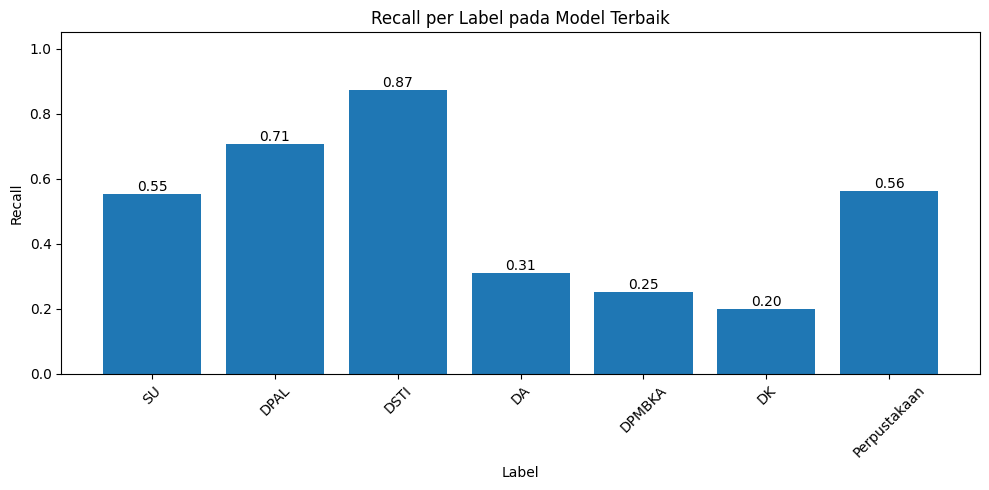

In [18]:
# ============================================================
# 18. Evaluasi per label untuk model terbaik
# ============================================================
precision_per_label = precision_score(Y_test, Y_pred_best, average=None, zero_division=0)
recall_per_label = recall_score(Y_test, Y_pred_best, average=None, zero_division=0)
f1_per_label = f1_score(Y_test, Y_pred_best, average=None, zero_division=0)
accuracy_per_label = [accuracy_score(Y_test[:, i], Y_pred_best[:, i]) for i in range(len(LABELS))]

per_label_df = pd.DataFrame({
    "Label": LABELS,
    "Is Minority Label": [label in MINORITY_LABELS for label in LABELS],
    "Positive Count Train Original": Y_train.sum(axis=0),
    "Positive Count Test": Y_test.sum(axis=0),
    "Precision": precision_per_label,
    "Recall": recall_per_label,
    "F1 score": f1_per_label,
    "Accuracy": accuracy_per_label
})

for col in ["Precision", "Recall", "F1 score", "Accuracy"]:
    per_label_df[col] = per_label_df[col].round(4)

print("Evaluasi per label untuk model terbaik:")
display(per_label_df)

plt.figure(figsize=(10, 5))
bars = plt.bar(per_label_df["Label"], per_label_df["Recall"])
plt.title("Recall per Label pada Model Terbaik")
plt.xlabel("Label")
plt.ylabel("Recall")
plt.ylim(0, 1.05)
plt.xticks(rotation=45)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


In [19]:
# ============================================================
# 19. Analisis fitur terpilih dan efisiensi subset
# ============================================================
selected_feature_df = pd.DataFrame({
    "Selected Feature Original Index": best_artifact["selected_idx"]
})

summary_efficiency_df = comparison_results_df[[
    "Experiment Group",
    "Method",
    "Selected Features",
    "Feature Ratio",
    "F1 Weighted",
    "F1 Macro",
    "Minority Recall",
    "Hamming Loss",
    "Research Score"
]].copy()

print("Ringkasan efisiensi fitur:")
display(summary_efficiency_df)

print("Contoh indeks fitur terpilih pada model terbaik:")
display(selected_feature_df.head(20))


Ringkasan efisiensi fitur:


,Experiment Group,Method,Selected Features,Feature Ratio,F1 Weighted,F1 Macro,Minority Recall,Hamming Loss,Research Score
0,Proposed Method,Imbalance-Aware Modified PSO,22,0.0286,0.7590,0.5510,0.3307,0.0599,0.4573
1,Statistical Selection,Pearson Correlation,50,0.0651,0.7722,0.5543,0.3088,0.0564,0.4540
2,Statistical Selection,Fisher Score,50,0.0651,0.7690,0.5506,0.3054,0.0577,0.4509
3,Statistical Selection,ANOVA,50,0.0651,0.7690,0.5506,0.3054,0.0577,0.4509
4,Statistical Selection,Fisher Score,100,0.1302,0.7735,0.5520,0.2950,0.0555,0.4465
5,Statistical Selection,ANOVA,100,0.1302,0.7735,0.5520,0.2950,0.0555,0.4465
6,Statistical Selection,Fisher Score,150,0.1953,0.7734,0.5508,0.2950,0.0551,0.4430
7,Statistical Selection,ANOVA,150,0.1953,0.7734,0.5508,0.2950,0.0551,0.4430
8,Statistical Selection,Dispersion Ratio,150,0.1953,0.7662,0.5503,0.2984,0.0566,0.4416
9,Statistical Selection,Pearson Correlation,200,0.2604,0.7779,0.5523,0.2950,0.0544,0.4415


Contoh indeks fitur terpilih pada model terbaik:


,Selected Feature Original Index
0,18
1,67
2,98
3,100
4,137
5,208
6,214
7,218
8,234
9,298


In [20]:
# ============================================================
# 20. Simpan hasil evaluasi, fitur terpilih, dan model terbaik
# ============================================================
best_model = best_artifact["model"]
best_selected_original_idx = best_artifact["selected_idx"]

model_package = {
    "embedding_backend": EMBEDDING_BACKEND,
    "model_name": MODEL_NAME,
    "tfidf_vectorizer": TFIDF_VECTORIZER,
    "labels": LABELS,
    "minority_labels": MINORITY_LABELS,
    "minority_label_indices": MINORITY_LABEL_INDICES,
    "text_column": TEXT_COL,
    "clean_text_column": CLEAN_TEXT_COL,
    "split_random_state": SPLIT_RANDOM_STATE,
    "best_overall_group": BEST_OVERALL_GROUP,
    "best_overall_method": BEST_OVERALL_METHOD,
    "best_statistical_id_for_stage1": BEST_STATISTICAL_ID,
    "best_selected_original_idx": best_selected_original_idx,
    "best_selected_feature_count": int(len(best_selected_original_idx)),
    "classifier": best_model,
    "label_distribution": label_distribution_df,
    "statistical_results": statistical_results_df,
    "metaheuristic_results": metaheuristic_results_df,
    "comparison_results": comparison_results_df,
    "per_label_results": per_label_df,
    "selected_feature_df": selected_feature_df,
    "config": {
        "test_size": TEST_SIZE,
        "feature_top_k_list": FEATURE_TOP_K_LIST,
        "default_candidate_top_k": DEFAULT_CANDIDATE_TOP_K,
        "min_selected_features": MIN_SELECTED_FEATURES,
        "max_feature_ratio": MAX_FEATURE_RATIO,
        "rf_n_estimators": RF_N_ESTIMATORS,
        "rf_max_depth": RF_MAX_DEPTH,
        "fitness_rf_n_estimators": FITNESS_RF_N_ESTIMATORS,
        "fitness_rf_max_depth": FITNESS_RF_MAX_DEPTH,
        "cv_splits": CV_SPLITS,
        "pso_pop_size": PSO_POP_SIZE,
        "pso_max_iter": PSO_MAX_ITER,
        "pso_patience": PSO_PATIENCE,
        "random_state": RANDOM_STATE,
        "objective_weights": {
            "weighted_f1": OBJ_W_WEIGHTED_F1,
            "macro_f1": OBJ_W_MACRO_F1,
            "minority_recall": OBJ_W_MINOR_RECALL,
            "hamming_loss": OBJ_W_HAMMING,
            "subset_size": OBJ_W_SUBSET_SIZE,
            "redundancy": OBJ_W_REDUNDANCY
        }
    }
}

joblib.dump(model_package, "best_rf_multilabel_model_IA_MPSO.joblib")

statistical_results_df.to_csv("hasil_seleksi_fitur_statistik.csv", index=False)
metaheuristic_results_df.to_csv("hasil_seleksi_fitur_metaheuristik.csv", index=False)
comparison_results_df.to_csv("hasil_perbandingan_semua_metode.csv", index=False)
per_label_df.to_csv("hasil_per_label_model_terbaik.csv", index=False)
selected_feature_df.to_csv("fitur_terpilih_model_terbaik.csv", index=False)
label_distribution_df.to_csv("distribusi_label.csv", index=False)

with pd.ExcelWriter("hasil_eksperimen_IA_MPSO.xlsx", engine="openpyxl") as writer:
    label_distribution_df.to_excel(writer, sheet_name="Distribusi Label", index=False)
    statistical_results_df.to_excel(writer, sheet_name="Statistik", index=False)
    metaheuristic_results_df.to_excel(writer, sheet_name="Metaheuristik", index=False)
    comparison_results_df.to_excel(writer, sheet_name="Perbandingan", index=False)
    per_label_df.to_excel(writer, sheet_name="Per Label", index=False)
    selected_feature_df.to_excel(writer, sheet_name="Fitur Terpilih", index=False)

print("File berhasil disimpan:")
print("1. best_rf_multilabel_model_IA_MPSO.joblib")
print("2. hasil_eksperimen_IA_MPSO.xlsx")
print("3. hasil_seleksi_fitur_statistik.csv")
print("4. hasil_seleksi_fitur_metaheuristik.csv")
print("5. hasil_perbandingan_semua_metode.csv")
print("6. hasil_per_label_model_terbaik.csv")
print("7. fitur_terpilih_model_terbaik.csv")
print("8. distribusi_label.csv")


File berhasil disimpan:
1. best_rf_multilabel_model_IA_MPSO.joblib
2. hasil_eksperimen_IA_MPSO.xlsx
3. hasil_seleksi_fitur_statistik.csv
4. hasil_seleksi_fitur_metaheuristik.csv
5. hasil_perbandingan_semua_metode.csv
6. hasil_per_label_model_terbaik.csv
7. fitur_terpilih_model_terbaik.csv
8. distribusi_label.csv
